# Neural policy targeting missed sales

Train a bounded neural residual policy directly for missed sales; validate integer orders and inspect fill rate.

Use the same workflow as the existing mean-forecast and percentile examples: generate standard rows, split, fit per item, inspect the policy, simulate, inspect decision rows, and plot item/aggregate missed sales.

Training requires `pip install -e ".[advanced]"`. Inference uses frozen numeric weights.


## Setup


In [1]:
from pathlib import Path
from dataclasses import replace, asdict
from collections import Counter
import itertools, math, random, statistics, time, tempfile
import sys

ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/"src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from replenishment import (
    InventoryState, BaseStockPolicy, ConstantOrderPolicy, CappedBaseStockPolicy, sSPolicy,
    ProjectedInventoryLevelPolicy, ProtectionPeriodQuantilePolicy,
    generate_standard_simulation_rows, split_standard_simulation_rows,
    standard_simulation_rows_to_dataframe, build_article_configs_from_standard_rows,
    simulate_replenishment, simulate_replenishment_for_articles,
    optimize_policy_candidates, RiskObjective, empirical_cvar,
    optimize_risk_sensitive_policy_candidates, build_replenishment_decisions_from_simulations,
    replenishment_decision_rows_to_dataframe, plot_replenishment_decisions,
)
plt.switch_backend("agg")
pd.set_option("display.max_columns",None)
PLOT_DIR=ROOT/"docs"/"plots"
PLOT_DIR.mkdir(exist_ok=True)


## Parameters


In [2]:
METHOD='structured_neural'
TITLE='Neural policy targeting missed sales'
n_unique_ids=3
periods=96
training_end_period=40
replenishment_start_period=64
review_period=1
seed=17
fixed_order_cost=0.0
training_epochs=40
training_target='missed_sales'


## Generate Sample Data

Use the public standard-row generator, then add reproducible seasonal,
intermittent and rising profiles. Evaluation actuals are sampled only for offline
scoring. `actuals` and simulated `demand` use the same realization so plots and
missed-sales metrics reconcile. Forecast inputs are supplied exogenously; they
are never replaced with future actuals.


In [3]:
rows=generate_standard_simulation_rows(
    n_unique_ids=n_unique_ids,periods=periods,start_date="2026-01-01",frequency_days=1,
    forecast_start_period=replenishment_start_period,
    history_mean=5,history_std=2,forecast_mean=5,forecast_std=1,
    lead_time=2,initial_on_hand=16,current_stock=16,
    holding_cost_per_unit=.4,stockout_cost_per_unit=8,
    order_cost_per_order=fixed_order_cost,seed=seed,
)
# Give the generated articles explicit, reproducible profiles. Future actuals
# are sampled for offline evaluation; they are never passed to policy fitting.
item_info=pd.DataFrame([
    dict(unique_id="A",item="Seasonal item",profile="seasonal",lead_time=2,current_stock=20),
    dict(unique_id="B",item="Intermittent spare part",profile="intermittent",lead_time=3,current_stock=8),
    dict(unique_id="C",item="Rising-demand item",profile="rising",lead_time=2,current_stock=24),
])
item_parameters=item_info.set_index("unique_id").to_dict("index")
date_to_period={ds:i for i,ds in enumerate(sorted({row.ds for row in rows}))}
rng=random.Random(seed+404)
prepared_rows=[]
for row in rows:
    t=date_to_period[row.ds]
    item=item_parameters[row.unique_id]
    actual=int(row.actuals) if row.actuals is not None else max(0,round(rng.gauss(5,2)))
    forecast=row.forecast
    if item["profile"]=="seasonal":
        uplift=[0,1,3,1,0,0,2,2][t%8]
        actual+=uplift; forecast+=uplift
    elif item["profile"]=="intermittent":
        actual=rng.choices([0,4,8],weights=[.75,.125,.125])[0]
        forecast=2
    else:
        actual+=t//16; forecast+=t//16
    # Plot actuals and simulated demand are the SAME draw, including evaluation.
    prepared_rows.append(replace(row,demand=actual,actuals=actual,forecast=forecast,
        forecast_percentiles={"p50":forecast,"p90":math.ceil(1.25*forecast)},
        lead_time=item["lead_time"],initial_on_hand=item["current_stock"],
        current_stock=item["current_stock"]))
rows=prepared_rows
df=standard_simulation_rows_to_dataframe(rows,library="pandas",include_demand=True)
assert len(df)==n_unique_ids*periods
assert df["actuals"].eq(df["demand"]).all()
display(item_info)
display(df.head(12))


,unique_id,item,profile,lead_time,current_stock
0,A,Seasonal item,seasonal,2,20
1,B,Intermittent spare part,intermittent,3,8
2,C,Rising-demand item,rising,2,24


,unique_id,ds,demand,forecast,actuals,holding_cost_per_unit,stockout_cost_per_unit,order_cost_per_order,lead_time,initial_on_hand,current_stock,is_forecast,forecast_p50,forecast_p90
0,A,2026-01-01,5,3,5,0.4,8,0.0,2,20,20,False,3,4
1,A,2026-01-02,6,7,6,0.4,8,0.0,2,20,20,False,7,9
2,A,2026-01-03,5,8,5,0.4,8,0.0,2,20,20,False,8,10
3,A,2026-01-04,5,6,5,0.4,8,0.0,2,20,20,False,6,8
4,A,2026-01-05,5,6,5,0.4,8,0.0,2,20,20,False,6,8
5,A,2026-01-06,3,5,3,0.4,8,0.0,2,20,20,False,5,7
6,A,2026-01-07,7,6,7,0.4,8,0.0,2,20,20,False,6,8
7,A,2026-01-08,3,8,3,0.4,8,0.0,2,20,20,False,8,10
8,A,2026-01-09,9,2,9,0.4,8,0.0,2,20,20,False,2,3
9,A,2026-01-10,7,8,7,0.4,8,0.0,2,20,20,False,8,10


## Split Training, Validation and Evaluation

Backtest rows cover the first 64 dates; model training uses the first 40 and
neural checkpoint validation the next 24. The last 32 dates are untouched
evaluation demand. Candidate searches and fitted distributions use training rows
only; neural validation selects checkpoints without contributing gradients.
Every split starts from the declared stock with an empty pipeline, zero warmup,
no terminal salvage and no post-horizon fulfillment. This is a reproducible
cold-start comparison, not a continuous simulation carrying state between splits.


In [4]:
backtest_rows,forecast_rows=split_standard_simulation_rows(rows)
training_rows=[row for row in backtest_rows if date_to_period[row.ds]<training_end_period]
validation_rows=[row for row in backtest_rows if date_to_period[row.ds]>=training_end_period]

def group_rows(values):
    return {uid:sorted([row for row in values if row.unique_id==uid],key=lambda row:row.ds)
            for uid in sorted({row.unique_id for row in values})}

train_by_article=group_rows(training_rows)
validation_by_article=group_rows(validation_rows)
eval_by_article=group_rows(forecast_rows)
assert max(row.ds for row in training_rows)<min(row.ds for row in validation_rows)
assert max(row.ds for row in validation_rows)<min(row.ds for row in forecast_rows)
assert all(not row.is_forecast for row in backtest_rows)
assert all(row.is_forecast for row in forecast_rows)
display(pd.DataFrame([
    dict(split=label,articles=len({row.unique_id for row in values}),rows=len(values),
         start=min(row.ds for row in values),end=max(row.ds for row in values))
    for label,values in [("training",training_rows),("validation",validation_rows),("evaluation",forecast_rows)]
]))

def row_costs(series):
    row=series[0]
    return dict(holding_cost_per_unit=row.holding_cost_per_unit,
                stockout_cost_per_unit=row.stockout_cost_per_unit,
                order_cost_per_order=row.order_cost_per_order)


,split,articles,rows,start,end
0,training,3,120,2026-01-01,2026-02-09
1,validation,3,72,2026-02-10,2026-03-05
2,evaluation,3,96,2026-03-06,2026-04-06


## Fit the Neural Policy per Article

The objective is mean missed units: a unit shortage penalty and zero other penalties. On fixed demand traces, this also maximises demand-weighted fill rate. It does not enforce a 95% threshold. Inventory and business costs remain visible.

Each item has its own model and seed. Forecast horizons are constructed from that split’s supplied forecast series, with last-value extension at the end. No evaluation actuals or next-split data enter training features.


In [5]:
from replenishment import (create_structured_neural_policy,train_hdpo,differentiable_rollout,
                          StructuredNeuralPolicy)

def forecast_vectors(series,horizon):
    # The synthetic forecast series is an exogenous horizon known at decision
    # time. Only forecasts, never future actuals, enter these features. Extend
    # the last supplied forecast at the end of each split; do not peek at the
    # next split's actuals or forecasts to build training features.
    values=tuple(row.forecast for row in series)
    return tuple(tuple(values[min(t+h+1,len(values)-1)] for h in range(horizon))
                 for t in range(len(values)))

def forecast_provider(series,horizon):
    vectors=forecast_vectors(series,horizon)
    return lambda state: vectors[state.period]


In [6]:
selected_policies={}
initial_policies={}
fitted_results={}
policy_records=[]
training_histories=[]
started=time.perf_counter()
for number,(uid,series) in enumerate(train_by_article.items()):
    validation_series=validation_by_article[uid]
    lead_time=series[0].lead_time
    horizon=max(1,lead_time)+review_period-1
    history=[row.demand for row in series]
    mean_demand=statistics.fmean(history)
    initial=create_structured_neural_policy(lead_time=lead_time,review_period=review_period,
        target_stock=0,residual_scale=max(4,math.ceil(mean_demand*horizon)),
        feature_scale=max(1,mean_demand*horizon),hidden_size=8,
        max_order_quantity=max(4,2*max(history)),use_forecast_target=True,
        forecast=forecast_provider(series,horizon),seed=seed+number)
    loss_costs=(dict(holding_cost_per_unit=0,stockout_cost_per_unit=1,order_cost_per_order=0)
                if training_target=="missed_sales" else row_costs(series))
    fit=train_hdpo(initial,training_demand=[history],
        validation_demand=[[row.demand for row in validation_series]],
        training_forecasts=[forecast_vectors(series,horizon)],
        validation_forecasts=[forecast_vectors(validation_series,horizon)],
        initial_on_hand=series[0].initial_on_hand,epochs=training_epochs,
        learning_rate=.025,regularization=0.0 if training_target=="missed_sales" else .001,
        seed=seed+number,**loss_costs)
    # Freeze weights, but supply the forecast horizon for the evaluation dates.
    selected_policies[uid]=fit.policy.with_forecast(forecast_provider(eval_by_article[uid],horizon))
    initial_policies[uid]=initial.with_forecast(forecast_provider(eval_by_article[uid],horizon))
    fitted_results[uid]=fit
    validation_policy=fit.policy.with_forecast(forecast_provider(validation_series,horizon))
    validation_sim=simulate_replenishment(periods=len(validation_series),
        demand=[row.demand for row in validation_series],initial_on_hand=series[0].initial_on_hand,
        lead_time=lead_time,policy=validation_policy,**loss_costs)
    assert abs(fit.validation_score-validation_sim.summary.total_cost)<1e-9
    assert fit.validation_score==min(epoch.validation_score for epoch in fit.history)
    policy_records.append(dict(unique_id=uid,policy=type(fit.policy).__name__,
        training_target=training_target,updates=len(fit.history)-1,selected_epoch=fit.selected_epoch,
        continuous_training_score=fit.training_continuous_score,
        exact_training_score=fit.training_exact_score,rounding_gap=fit.rounding_gap,
        validation_score=fit.validation_score,validation_fill_rate=validation_sim.summary.fill_rate,
        runtime_seconds=fit.runtime_seconds,parameters=asdict(fit.policy.config)))
    training_histories.extend(dict(unique_id=uid,epoch=epoch.epoch,
        continuous_training_score=epoch.training_objective,exact_validation_score=epoch.validation_score)
        for epoch in fit.history)
fit_runtime_seconds=time.perf_counter()-started
policy_df=pd.DataFrame(policy_records)
training_history_df=pd.DataFrame(training_histories)
print(f"Independent model training runtime: {fit_runtime_seconds:.3f} seconds")
display(training_history_df[training_history_df.epoch%10==0])


Independent model training runtime: 3.571 seconds


,unique_id,epoch,continuous_training_score,exact_validation_score
0,A,0,41.000000,12.0
10,A,10,0.000000,0.0
20,A,20,0.000000,0.0
30,A,30,0.000000,0.0
40,A,40,0.000000,0.0
41,B,0,24.000000,6.0
51,B,10,16.290758,2.0
61,B,20,16.019826,2.0
71,B,30,16.006515,2.0
81,B,40,16.004090,2.0


## Inspect the Selected Policy

Inspect selected parameters and training diagnostics, then probe order decisions
at the first evaluation date for hypothetical on-hand levels with no pipeline.
Change `example_id` to inspect another generated article.


In [7]:
display(policy_df)
example_id=df["unique_id"].iloc[0]  # Change this to inspect another article.
example_policy=selected_policies[example_id]
print("Example article:",example_id,item_parameters[example_id]["item"])
print("Policy:",example_policy.config if hasattr(example_policy,"config") else example_policy)

# Inspect hypothetical decisions at the first evaluation date, with no pipeline.
# This probes the selected policy, not future realized demand.
probe_limit=math.ceil(max(1,statistics.fmean(row.demand for row in train_by_article[example_id]))
                      *(max(1,eval_by_article[example_id][0].lead_time)+review_period)*2)
policy_response_df=pd.DataFrame([
    dict(on_hand=stock,on_order=0,order_quantity=example_policy.order_quantity_for(
        InventoryState(period=0,on_hand=stock,on_order=0,backorders=0)))
    for stock in range(0,probe_limit+1,2)
])
display(policy_response_df)


Example article: A Seasonal item
Policy: NeuralPolicyConfig(lead_time=2, target_stock=0.0, review_period=1, forecast_horizon=2, hidden_size=8, residual_scale=13.0, feature_scale=12.75, max_order_quantity=22, use_forecast_target=True)


,unique_id,policy,training_target,updates,selected_epoch,continuous_training_score,exact_training_score,rounding_gap,validation_score,validation_fill_rate,runtime_seconds,parameters
0,A,StructuredNeuralPolicy,missed_sales,40,4,12.192696,9.0,-3.192696,0.0,1.000000,1.557002,"{'lead_time': 2, 'target_stock': 0.0, 'review_..."
1,B,StructuredNeuralPolicy,missed_sales,40,6,17.602486,16.0,-1.602486,2.0,0.928571,0.718293,"{'lead_time': 3, 'target_stock': 0.0, 'review_..."
2,C,StructuredNeuralPolicy,missed_sales,40,3,8.853561,6.0,-2.853561,0.0,1.000000,0.588394,"{'lead_time': 2, 'target_stock': 0.0, 'review_..."


,on_hand,on_order,order_quantity
0,0,0,21
1,2,0,19
2,4,0,17
3,6,0,15
4,8,0,13
5,10,0,11
6,12,0,9
7,14,0,7
8,16,0,5
9,18,0,4


## Run Evaluation Simulations

Use the standard-row config builder and public multi-article simulator. The
weights/parameters are frozen. Evaluation rows start from `current_stock`.
No stock, budget or capacity is shared between articles.


In [8]:
eval_configs=build_article_configs_from_standard_rows(
    forecast_rows,policies=selected_policies,use_current_stock=True,
)
eval_simulations=simulate_replenishment_for_articles(eval_configs)

def simulation_summary(simulations,model):
    return [dict(unique_id=uid,model=model,total_demand=result.summary.total_demand,
        fulfilled_units=result.summary.total_fulfilled,missed_units=result.summary.total_lost_sales,
        fill_rate=result.summary.fill_rate,average_stock=result.summary.average_on_hand,
        peak_stock=max(s.ending_on_hand for s in result.snapshots),
        order_frequency=sum(s.order_placed>0 for s in result.snapshots)/len(result.snapshots),
        total_cost=result.summary.total_cost)
        for uid,result in simulations.items()]

evaluation_summary_df=pd.DataFrame(simulation_summary(eval_simulations,"Selected policy"))
display(evaluation_summary_df.round(4))


,unique_id,model,total_demand,fulfilled_units,missed_units,fill_rate,average_stock,peak_stock,order_frequency,total_cost
0,A,Selected policy,188,183,5,0.9734,5.6562,17,0.9688,112.4
1,B,Selected policy,64,48,16,0.7500,5.0938,10,0.5312,193.2
2,C,Selected policy,294,294,0,1.0000,5.5312,14,1.0000,70.8


In [9]:
initial_eval_configs=build_article_configs_from_standard_rows(
    forecast_rows,policies=initial_policies,use_current_stock=True,
)
initial_simulations=simulate_replenishment_for_articles(initial_eval_configs)
before_after_df=pd.DataFrame(simulation_summary(initial_simulations,"Before training")
    +simulation_summary(eval_simulations,"Selected neural policy"))
display(before_after_df.sort_values(["unique_id","model"]).round(4))


,unique_id,model,total_demand,fulfilled_units,missed_units,fill_rate,average_stock,peak_stock,order_frequency,total_cost
0,A,Before training,188,165,23,0.8777,2.3125,17,0.9375,213.6
3,A,Selected neural policy,188,183,5,0.9734,5.6562,17,0.9688,112.4
1,B,Before training,64,32,32,0.5000,3.3750,8,0.2500,299.2
4,B,Selected neural policy,64,48,16,0.7500,5.0938,10,0.5312,193.2
2,C,Before training,294,275,19,0.9354,2.2188,14,1.0000,180.4
5,C,Selected neural policy,294,294,0,1.0000,5.5312,14,1.0000,70.8


## Inspect Replenishment Decisions and Missed Sales

The standard decision table contains order quantities, receipts, stock before
and after demand, outstanding orders, and missed units. Reconcile it to simulator
snapshots before plotting. Stockouts are lost sales, not carried backorders.


In [10]:
decision_rows=build_replenishment_decisions_from_simulations(forecast_rows,eval_simulations)
decision_df=replenishment_decision_rows_to_dataframe(decision_rows,library="pandas")
assert len(decision_df)==len(forecast_rows)
assert int(decision_df.missed_sales.sum())==sum(r.summary.total_lost_sales for r in eval_simulations.values())
for uid,result in eval_simulations.items():
    article_decisions=decision_df[decision_df.unique_id==uid].sort_values("ds")
    assert article_decisions.missed_sales.tolist()==[s.lost_sales for s in result.snapshots]
    assert article_decisions.ending_stock.tolist()==[s.ending_on_hand for s in result.snapshots]
    assert article_decisions.starting_stock.tolist()==[s.starting_on_hand for s in result.snapshots]
    assert article_decisions.demand.tolist()==[row.demand for row in eval_by_article[uid]]
columns=["unique_id","ds","demand","quantity","incoming_stock","starting_stock",
         "ending_stock","on_order","missed_sales","reorder_point","order_up_to"]
display(decision_df.loc[decision_df.unique_id==example_id,columns].head(16))


,unique_id,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,reorder_point,order_up_to
0,A,2026-03-06,3,4,0,20,17,4,0,None,None
1,A,2026-03-07,4,2,0,17,13,6,0,None,None
2,A,2026-03-08,10,4,4,17,7,6,0,None,None
3,A,2026-03-09,4,3,2,9,5,7,0,None,None
4,A,2026-03-10,3,9,4,9,6,12,0,None,None
5,A,2026-03-11,5,8,3,9,4,17,0,None,None
6,A,2026-03-12,8,4,9,13,5,12,0,None,None
7,A,2026-03-13,5,5,8,13,8,9,0,None,None
8,A,2026-03-14,3,5,4,12,9,10,0,None,None
9,A,2026-03-15,5,3,5,14,9,8,0,None,None


## Plot Example Articles

Use `plot_replenishment_decisions`, just like the existing notebooks. The shared
helper plots actuals/forecasts, stock and orders; when an item has missed sales,
it adds daily loss, cumulative loss, and cumulative missed-demand share. A
zero-loss item may omit those extra panels; its zero loss remains in the tables.


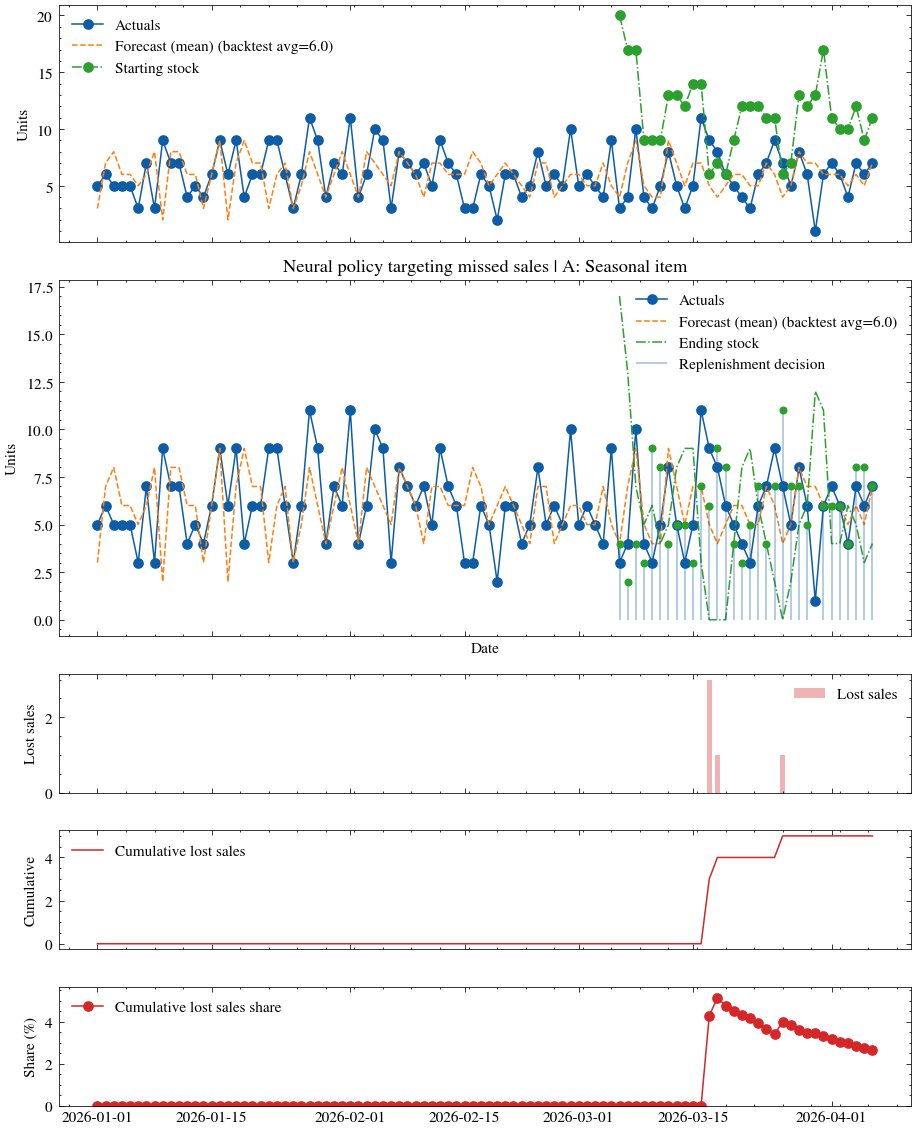

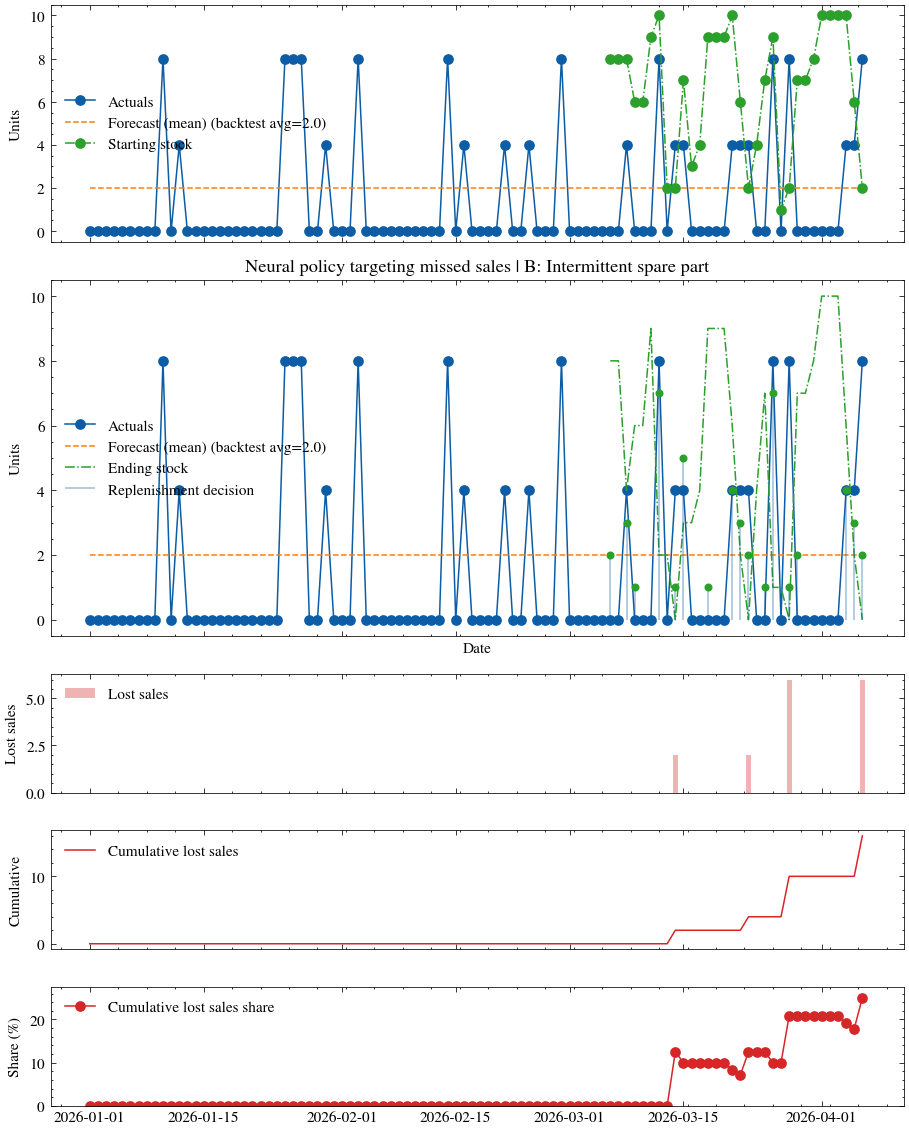

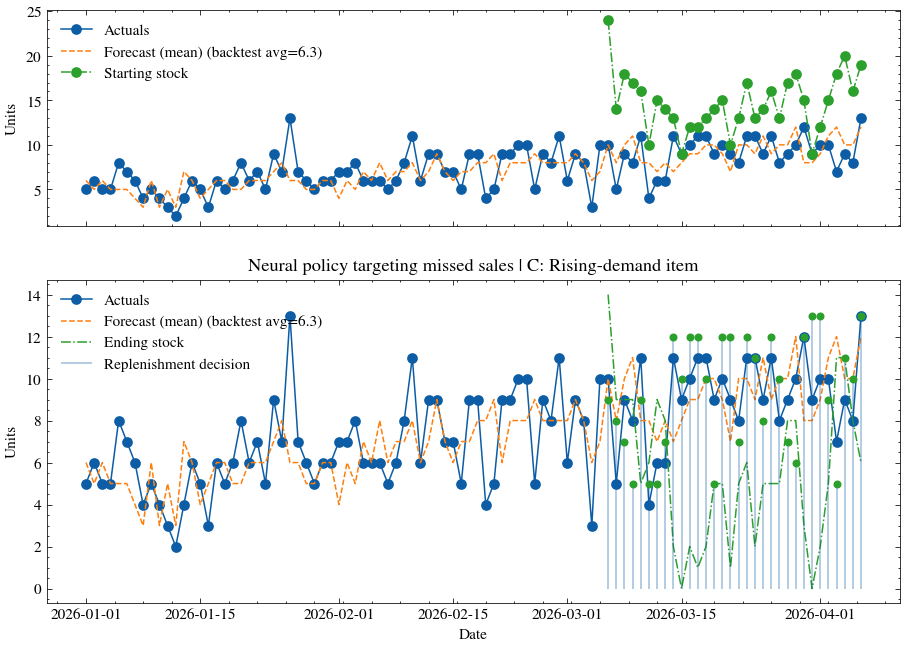

In [11]:
example_ids=sorted(decision_df["unique_id"].unique())[:3]
for uid in example_ids:
    ax=plot_replenishment_decisions(df,decision_df,unique_id=uid,
        title=f"{TITLE} | {uid}: {item_parameters[uid]['item']}",decision_style="line")
    figure=ax.figure
    path=PLOT_DIR/f"{METHOD}_standard_{uid}.png"
    figure.savefig(path,dpi=110,bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(figure)


## Plot Overall Demand, Stock and Missed Sales

Use the same helper with `aggregate=True`. The totals sum independently simulated
item stock and losses; excess stock of one item cannot satisfy another. Overall
fill rate is demand-weighted. The chart always includes missed-sales panels,
including zero losses, and the plotted cumulative loss/share is checked against
the simulation totals.


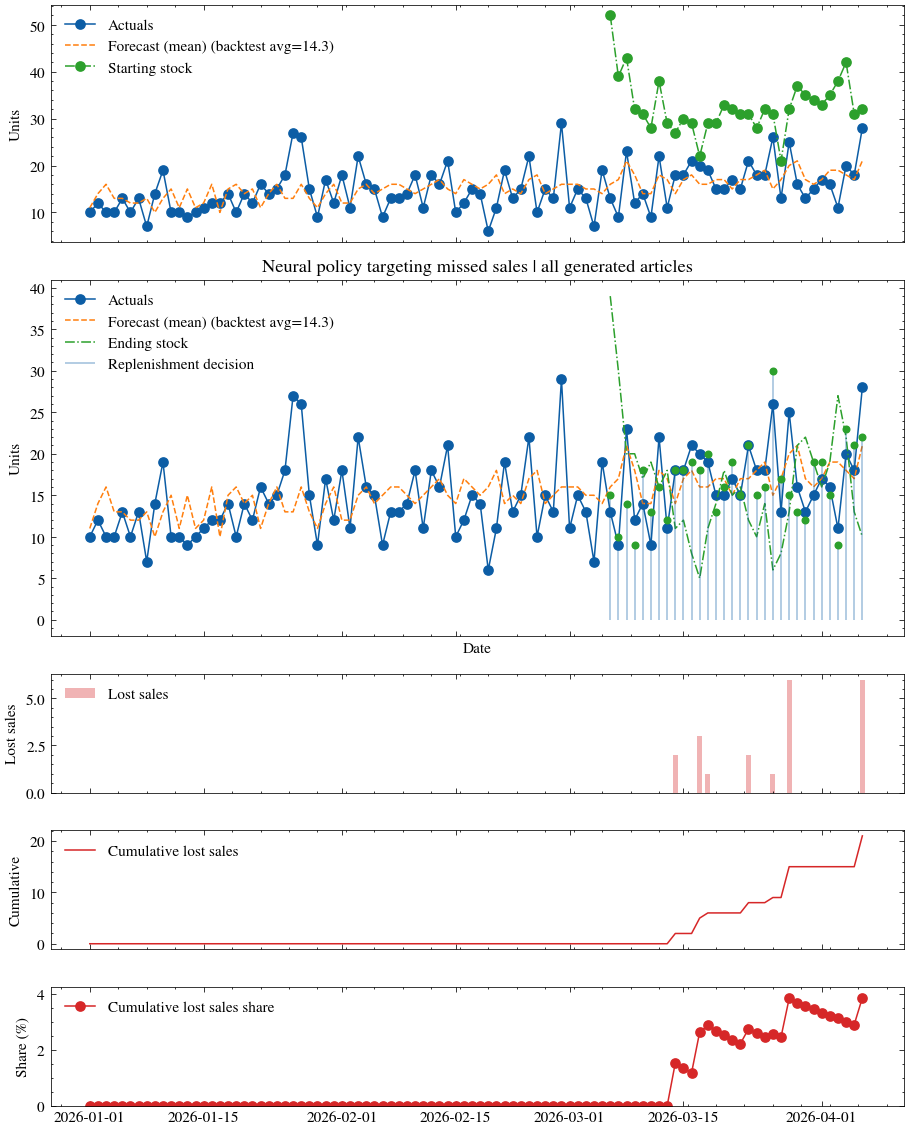

,articles,evaluation_periods,total_demand,fulfilled_units,missed_units,fill_rate,average_total_stock,peak_total_stock,ending_total_stock,ending_pipeline,total_cost
0,3,32,546,525,21,0.9615,16.2812,39,10,47,376.4


,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,fulfilled_units
0,2026-03-06,13,15,0,52,39,15,0,13
1,2026-03-07,9,10,0,39,30,25,0,9
2,2026-03-08,23,14,13,43,20,26,0,23
3,2026-03-09,12,9,12,32,20,23,0,12
4,2026-03-10,14,18,11,31,17,30,0,14
5,2026-03-11,9,13,11,28,19,32,0,9
6,2026-03-12,22,16,19,38,16,29,0,22
7,2026-03-13,11,12,13,29,18,28,0,11
8,2026-03-14,18,18,9,27,11,37,2,16
9,2026-03-15,18,18,19,30,12,36,0,18


In [12]:
# Sum independently simulated decisions; stock is never pooled between articles.
ax=plot_replenishment_decisions(df,decision_df,aggregate=True,
    title=f"{TITLE} | all generated articles",decision_style="line")
figure=ax.figure
# Reconcile plotted cumulative missed sales with the actual simulation totals.
cumulative_line=next(line for axis in figure.axes for line in axis.lines
                     if line.get_label()=="Cumulative lost sales")
share_line=next(line for axis in figure.axes for line in axis.lines
               if line.get_label()=="Cumulative lost sales share")
total_demand=sum(result.summary.total_demand for result in eval_simulations.values())
total_missed=sum(result.summary.total_lost_sales for result in eval_simulations.values())
assert abs(float(cumulative_line.get_ydata()[-1])-total_missed)<1e-9
assert abs(float(share_line.get_ydata()[-1])-(100*total_missed/total_demand if total_demand else 0))<1e-9
path=PLOT_DIR/f"{METHOD}_standard_aggregate.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)

overall_daily=decision_df.groupby("ds",as_index=False)[
    ["demand","quantity","incoming_stock","starting_stock","ending_stock","on_order","missed_sales"]
].sum()
overall_daily["fulfilled_units"]=overall_daily.demand-overall_daily.missed_sales
overall_summary_df=pd.DataFrame([dict(articles=len(eval_simulations),evaluation_periods=len(overall_daily),
    total_demand=total_demand,fulfilled_units=total_demand-total_missed,missed_units=total_missed,
    fill_rate=(1-total_missed/total_demand if total_demand else 1),
    average_total_stock=overall_daily.ending_stock.mean(),peak_total_stock=overall_daily.ending_stock.max(),
    ending_total_stock=overall_daily.ending_stock.iloc[-1],ending_pipeline=overall_daily.on_order.iloc[-1],
    total_cost=sum(result.summary.total_cost for result in eval_simulations.values()))])
display(overall_summary_df.round(4))
display(overall_daily.head(12))


## Continuous versus Integer Deployment

These are the same selected models and evaluation traces. Rounding can change both service and cost; report the gap rather than assuming continuous training outcomes transfer.


In [13]:
# Same selected model/data, continuous versus integer deployment.
diagnostic_records=[]
for uid,fit in fitted_results.items():
    series=eval_by_article[uid]
    horizon=max(1,series[0].lead_time)+review_period-1
    loss_costs=(dict(holding_cost_per_unit=0,stockout_cost_per_unit=1,order_cost_per_order=0)
                if training_target=="missed_sales" else row_costs(series))
    relaxed=differentiable_rollout(selected_policies[uid],[[row.demand for row in series]],
        forecasts=[forecast_vectors(series,horizon)],initial_on_hand=series[0].current_stock,**loss_costs)
    exact=simulate_replenishment(periods=len(series),demand=[row.demand for row in series],
        initial_on_hand=series[0].current_stock,lead_time=series[0].lead_time,
        policy=selected_policies[uid],**loss_costs)
    continuous_score=relaxed.costs[0].detach().item()
    diagnostic_records.append(dict(unique_id=uid,objective=training_target,
        continuous_evaluation_score=continuous_score,exact_integer_score=exact.summary.total_cost,
        rounding_gap=exact.summary.total_cost-continuous_score))
display(pd.DataFrame(diagnostic_records).round(4))

with tempfile.TemporaryDirectory() as directory:
    path=Path(directory)/"neural_policy.json"
    selected_policies[example_id].save(path)
    loaded=StructuredNeuralPolicy.load(path,forecast=forecast_provider(
        eval_by_article[example_id],selected_policies[example_id].forecast_horizon))
    probe=InventoryState(0,eval_by_article[example_id][0].current_stock,0,0)
    assert loaded.order_quantity_for(probe)==selected_policies[example_id].order_quantity_for(probe)
print("Safe numeric JSON deployment verified.")


Safe numeric JSON deployment verified.


,unique_id,objective,continuous_evaluation_score,exact_integer_score,rounding_gap
0,A,missed_sales,6.6844,5.0,-1.6844
1,B,missed_sales,19.2754,16.0,-3.2754
2,C,missed_sales,1.8512,0.0,-1.8512


## Verification Appendix

Check the missed-sales/fill-rate identity on a hand-calculated stockout case.


In [14]:
check=simulate_replenishment(periods=3,demand=[2,3,2],initial_on_hand=1,lead_time=0,
    policy=BaseStockPolicy(5),holding_cost_per_unit=0,stockout_cost_per_unit=1)
assert check.summary.total_lost_sales==check.summary.total_cost==1
assert abs(check.summary.fill_rate-(1-1/7))<1e-12
print("Missed-sales objective and fill-rate identity verified.")


Missed-sales objective and fill-rate identity verified.


## Interpretation

These synthetic outcomes illustrate the workflow, not a universal policy ranking.
Service-only optimisation can increase inventory and business cost, especially for
intermittent items. Models/distributions and finite candidate budgets have explicit
limitations. No shared/global constraints or solvers are introduced. Review cadence
is independent of time aggregation; these policies do not silently aggregate demand.
See [item-policy semantics](../docs/item_level_policies.md) and
[advanced methods](../docs/advanced_item_policies.md) for assumptions and API details.
